# Ringdown Lab: when does ignoring the overtone matter?

**Question.** At what signal-to-noise ratio (SNR) does the bias from a slightly wrong model
(ignoring the overtone) become larger than the error caused by noise, when measuring a
ringing black hole?

After two black holes merge, the new black hole "rings" like a struck bell. The ringing is
a sum of **quasi-normal modes**: damped sinusoids. The loudest is the fundamental **220**
mode. Right after the peak there is also the **221 overtone**, which dies about three times
faster. If we fit only the 220 mode, the leftover overtone pushes our answer away from
the truth. That push is the **bias**. Noise also moves the answer around randomly; that is the
**noise error**. Noise error shrinks as the signal gets louder (higher SNR), but the bias does
not. So above some SNR the bias must win. This notebook finds that SNR.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from ringdown_lab.qnm import qnm, REMNANT_MASS, REMNANT_SPIN
from ringdown_lab.signal import damped_sinusoid, time_axis, two_mode
from ringdown_lab.noise import white_noise, snr, scale_to_snr
from ringdown_lab.fit import fit_two_mode

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## Check 1: mode frequencies and damping times

Berti, Cardoso & Will (2006) fits for a remnant with M = 62.7 solar masses and spin 0.68.
Expected: 220 ≈ 271.4 Hz, 3.76 ms; 221 ≈ 265.4 Hz, 1.24 ms.

In [2]:
f0, tau0 = qnm("220", REMNANT_MASS, REMNANT_SPIN)
f1, tau1 = qnm("221", REMNANT_MASS, REMNANT_SPIN)
print(f"220: f = {f0:.2f} Hz, tau = {tau0*1e3:.3f} ms")
print(f"221: f = {f1:.2f} Hz, tau = {tau1*1e3:.3f} ms")

220: f = 271.41 Hz, tau = 3.759 ms
221: f = 265.41 Hz, tau = 1.238 ms


## Check 2: the signal

Both modes with amplitude 1 and phase 0, so at t = 0 the signal is 1 + 1 = 2.

h(0) = 2.0


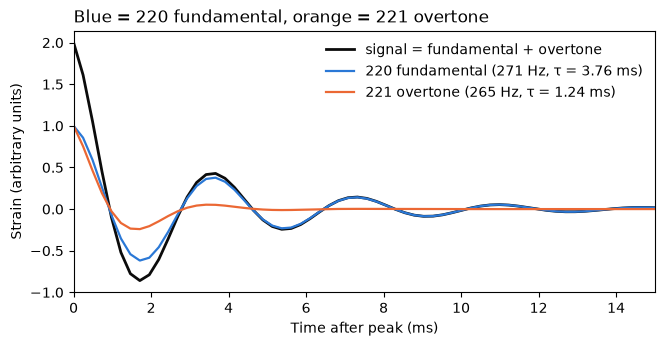

In [3]:
t = time_axis()
true = np.array([1, 0, f0, tau0, 1, 0, f1, tau1])
h = two_mode(t, *true)
print("h(0) =", h[0])

h220 = damped_sinusoid(t, *true[:4])     # fundamental only
h221 = damped_sinusoid(t, *true[4:])     # overtone only
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(t * 1e3, h, color="#0b0b0b", lw=2, label="signal = fundamental + overtone")
ax.plot(t * 1e3, h220, color="#2a78d6", lw=1.6, label=f"220 fundamental ({f0:.0f} Hz, τ = {tau0*1e3:.2f} ms)")
ax.plot(t * 1e3, h221, color="#eb6834", lw=1.6, label=f"221 overtone ({f1:.0f} Hz, τ = {tau1*1e3:.2f} ms)")
ax.set_xlim(0, 15)
ax.set_xlabel("Time after peak (ms)")
ax.set_ylabel("Strain (arbitrary units)")
ax.set_title("Blue = 220 fundamental, orange = 221 overtone", loc="left")
ax.legend(frameon=False)
plt.show()

## Check 3: noise and SNR

White noise should have standard deviation 1, and `scale_to_snr` should hit the target SNR.

noise std = 1.0001285040531447
SNR after scaling to 50 = 50.00000000000001


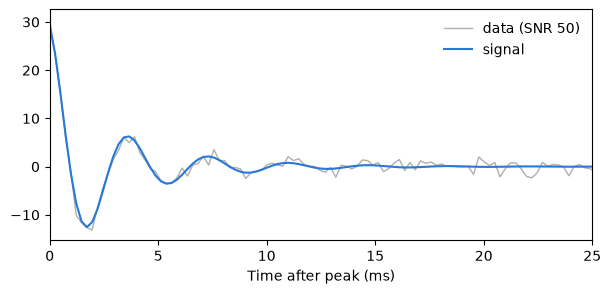

In [4]:
rng = np.random.default_rng(0)
print("noise std =", white_noise(100_000, 1.0, rng).std())
print("SNR after scaling to 50 =", snr(scale_to_snr(h, 50)))

data = scale_to_snr(h, 50) + white_noise(len(t), 1.0, rng)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t * 1e3, data, color="#b0afa9", lw=1, label="data (SNR 50)")
ax.plot(t * 1e3, scale_to_snr(h, 50), color="#2a78d6", lw=1.5, label="signal")
ax.set_xlim(0, 25)
ax.set_xlabel("Time after peak (ms)")
ax.legend(frameon=False)
plt.show()

## Check 4: a fit with no noise gets the right answer

If the fitting code is correct, fitting the clean signal must give back the true values,
even when we start 8-9% away.

In [5]:
start = true * np.array([1, 1, 1.08, 0.92, 1, 1, 0.93, 1.09])
params, ok = fit_two_mode(t, h, start)
for name, x, y in zip("a0 b0 f0 tau0 a1 b1 f1 tau1".split(), true, params):
    print(f"{name:5s} true {x:11.6g}   fit {y:11.6g}")

a0    true           1   fit           1
b0    true           0   fit -8.15128e-15
f0    true     271.413   fit     271.413
tau0  true  0.00375888   fit  0.00375888
a1    true           1   fit           1
b1    true           0   fit 3.02818e-14
f1    true     265.413   fit     265.413
tau1  true  0.00123762   fit  0.00123762


## Results

All numbers come from `python run_build.py` (N = 200 noise realisations per point),
saved in `results/results.json`.

In [6]:
res = json.loads((ROOT / "results" / "results.json").read_text())
print("Experiment A: two-mode fits")
print(f"{'SNR':>5} {'f221 error (Hz)':>16} {'Fisher (Hz)':>12} {'lost (%)':>9}")
for r in res["experiment_a"]["rows"]:
    print(f"{r['snr']:>5} {r['f221_error_hz']:>16.1f} {r['f221_fisher_hz']:>12.1f} {r['percent_lost']:>9.1f}")
print(f"log-log slope above SNR 50: {res['experiment_a']['slope_above_snr_50']:.2f}  (expected about -1)")
print()
print("Experiment B: fit only the 220 mode")
print(f"{'start (ms)':>10} {'bias tau220 (%)':>16} {'crossover SNR':>14}")
for r in res["experiment_b"]:
    print(f"{r['start_ms']:>10} {r['bias_percent']:>16.2f} {r['crossover_snr']:>14.1f}")

Experiment A: two-mode fits
  SNR  f221 error (Hz)  Fisher (Hz)  lost (%)
    8             85.3        558.1      40.5
   10             70.7        446.4      34.0
   15             95.7        297.6      36.5
   20             92.4        223.2      36.0
   30             67.7        148.8      36.5
   50            113.6         89.3      47.0
   80             52.2         55.8      32.0
  120             45.2         37.2      25.0
  200             21.0         22.3       5.0
  300             14.9         14.9       0.0
log-log slope above SNR 50: -1.11  (expected about -1)

Experiment B: fit only the 220 mode
start (ms)  bias tau220 (%)  crossover SNR
         0           -34.70            4.4
         1           -19.89           15.9
         2           -13.27           37.2
         3            -8.47           73.5
         4            -4.77          216.1
         6            -1.60         1311.0
         8            -0.53        10420.9


### Colour code used in every figure

**Blue = 220 fundamental, orange = 221 overtone.** Figure 00 shows the two modes on their own.

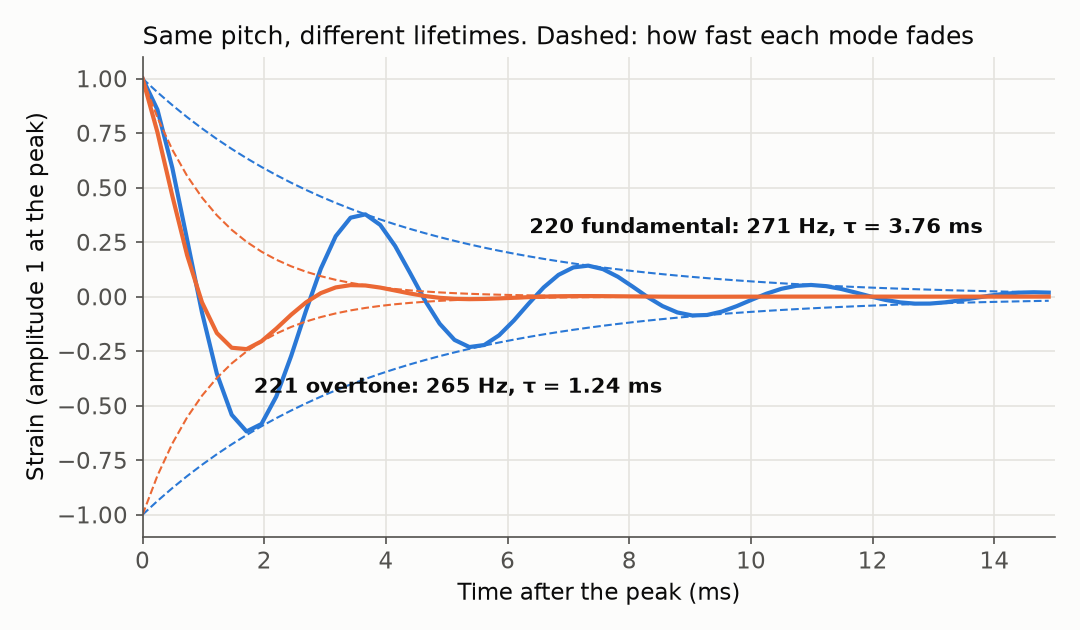

In [7]:
display(Image(ROOT / "figures" / "00_two_modes.png"))

### Experiment A: can we measure the overtone?

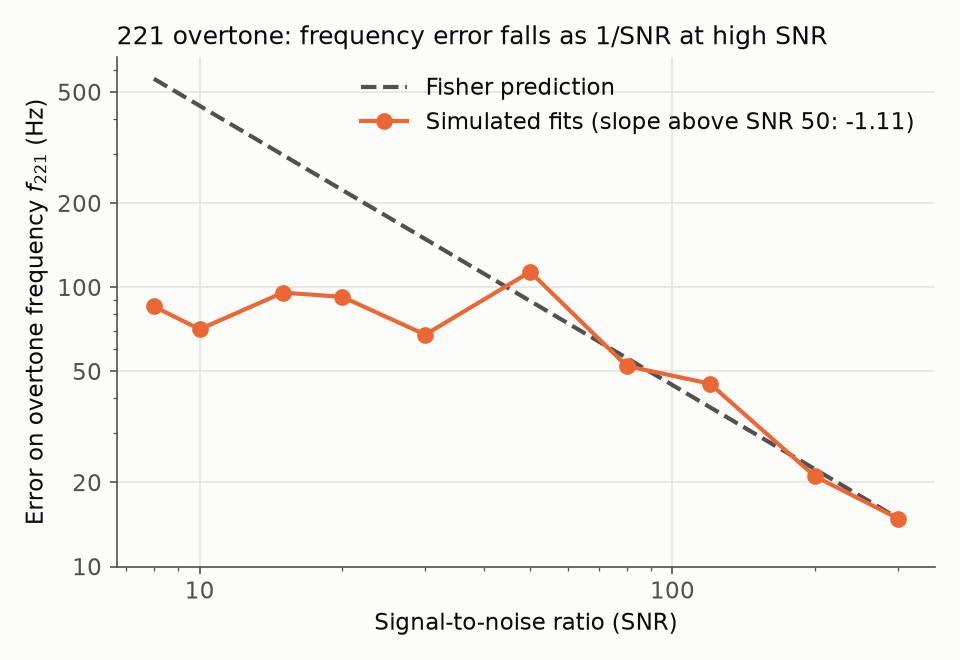

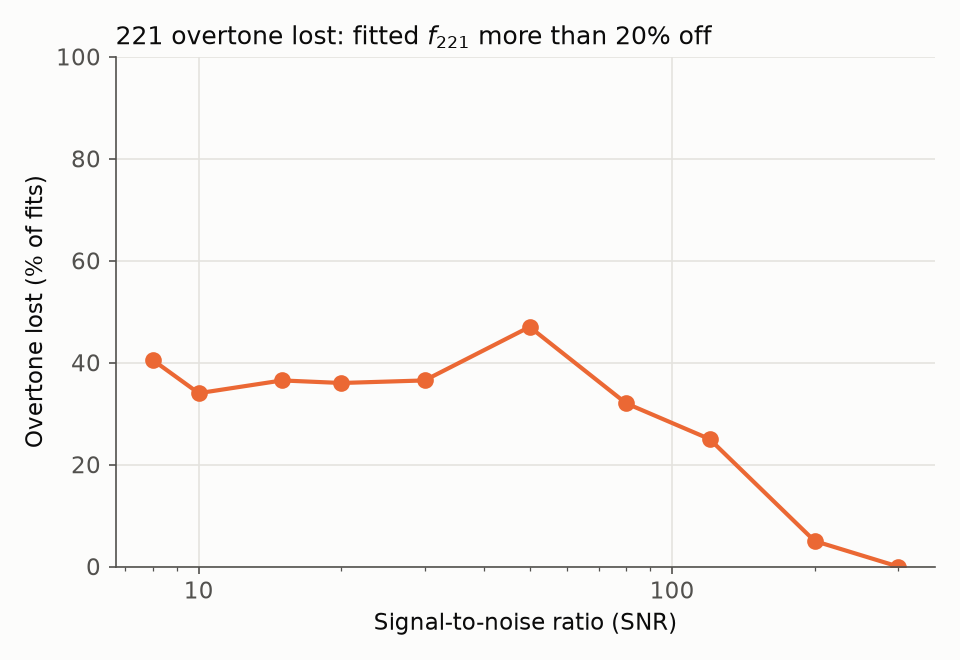

In [8]:
display(Image(ROOT / "figures" / "01_overtone_error_vs_snr.png"))
display(Image(ROOT / "figures" / "02_overtone_lost_vs_snr.png"))

### Experiment B: bias from ignoring the overtone vs noise error

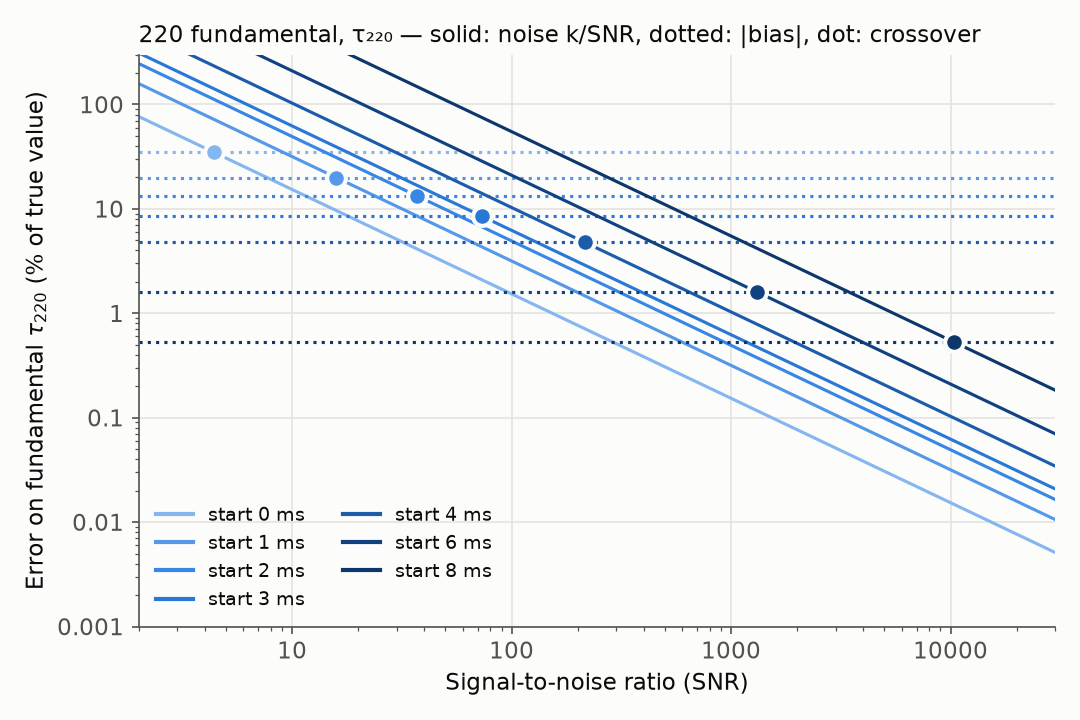

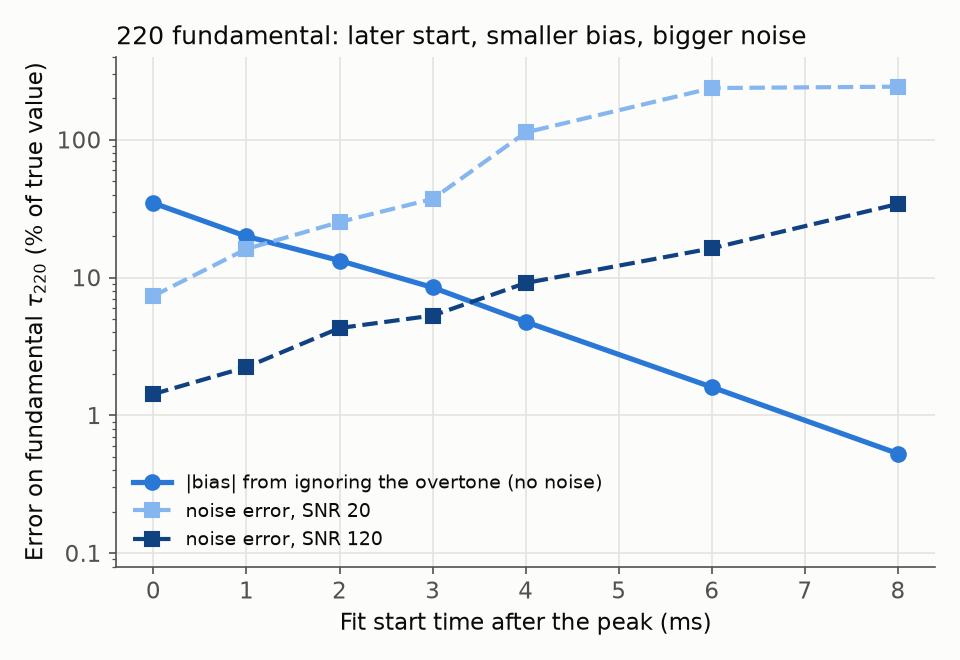

In [9]:
display(Image(ROOT / "figures" / "03_bias_vs_noise_crossover.png"))
display(Image(ROOT / "figures" / "04_bias_and_noise_vs_start.png"))

## Part 2: can you hear the overtone?

Experiment B says the bias wins above a crossover SNR. But at that SNR, would we even know
the overtone is there? Two ways to answer:

- **Significance Z** (Fisher matrix): the overtone amplitude divided by its expected error.
  Z ≥ 3 is the "3σ" bar used for GW150914 and GW250114.
- **Δχ² test** (Experiment C, simulated): how much better two modes fit the noisy data than
  one. The threshold is set so pure noise passes only 1% of the time.

In [10]:
det = json.loads((ROOT / "results" / "detection.json").read_text())
print(f"Delta-chi2 threshold (1% false alarms): {det['experiment_c']['threshold']:.2f}")
print(f"{'start':>5} {'SNR':>5} {'detected':>9} {'false alarm':>12} {'Fisher Z':>9}")
for r in det["experiment_c"]["rows"]:
    print(f"{r['start_ms']:>5} {r['snr']:>5} {r['percent_detected']:>8.1f}% {r['percent_false_alarm']:>11.1f}% {r['fisher_Z']:>9.2f}")
print()
print("Blind spot (ratio 1, phase 0):")
print(f"{'start (ms)':>10} {'bias beats noise above SNR':>27} {'heard (Z>=3) above SNR':>24}")
for r in det["experiment_d"]["blind_spot"]:
    print(f"{r['start_ms']:>10} {r['crossover_snr']:>27.1f} {r['snr_heard']:>24.1f}")

Delta-chi2 threshold (1% false alarms): 15.70
start   SNR  detected  false alarm  Fisher Z
    0     8      1.0%         1.0%      0.29
    0    10      0.5%         0.0%      0.37
    0    15      3.5%         2.0%      0.55
    0    20      5.0%         1.5%      0.73
    0    30      9.0%         0.5%      1.10
    0    50     54.5%         1.0%      1.83
    0    80     97.0%         1.0%      2.93
    0   120    100.0%         0.5%      4.39
    0   200    100.0%         1.5%      7.32
    0   300    100.0%         1.0%     10.98
    2     8      0.0%         1.0%      0.05
    2    10      2.0%         2.0%      0.06
    2    15      1.5%         0.5%      0.10
    2    20      1.0%         0.5%      0.13
    2    30      0.5%         1.0%      0.19
    2    50      2.0%         0.5%      0.32
    2    80      2.0%         1.0%      0.52
    2   120      4.0%         0.5%      0.78
    2   200     21.5%         2.0%      1.29
    2   300     68.5%         1.0%      1.94

Blind sp

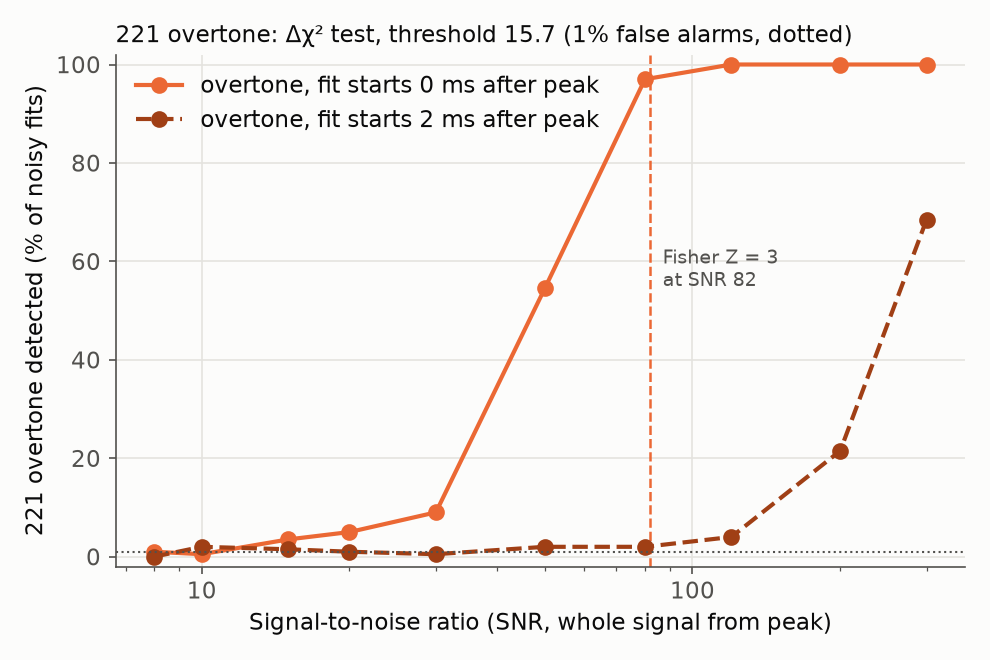

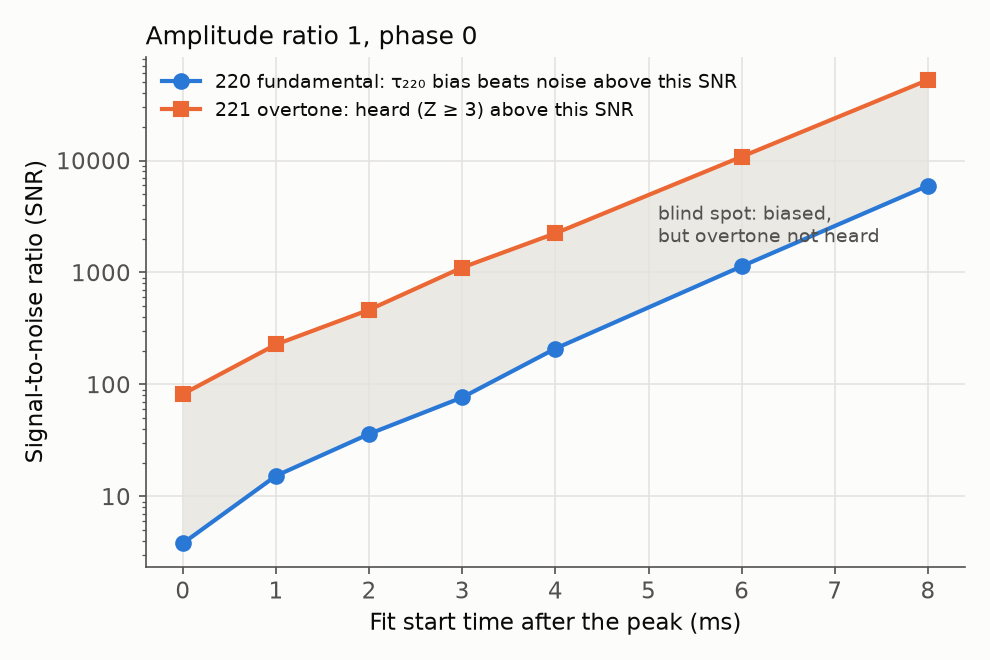

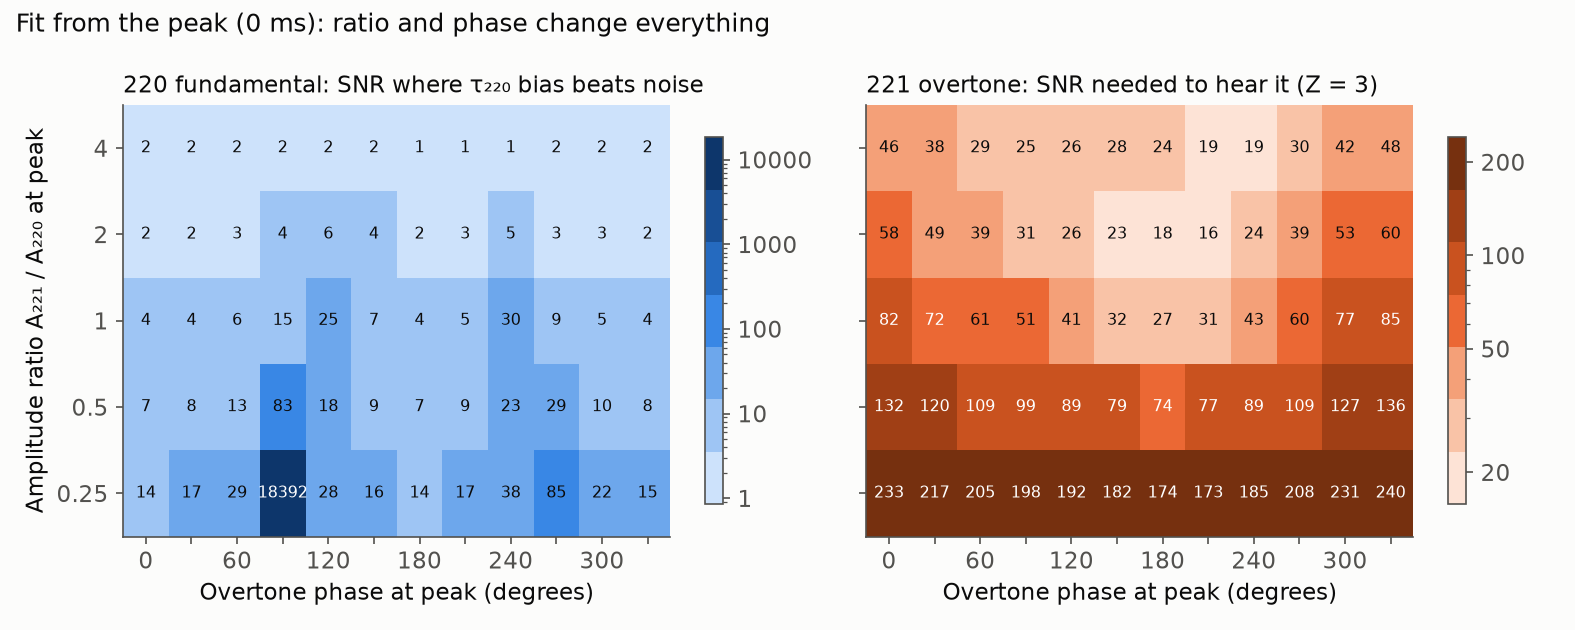

In [11]:
for name in ["05_detection_vs_snr.png", "06_blind_spot_vs_start.png", "07_ratio_phase_maps.png"]:
    display(Image(ROOT / "figures" / name))

### Try it yourself

Open `app/index.html` (Overtone Explorer) in a browser. Change the mass, spin, overtone
amplitude and phase, SNR and fit start time, and it explains whether you can hear the
overtone, and why. Its JavaScript physics matches this Python code to better than 0.01%.

## What I found

